# 04 · Seniority and the junior share

How much of IT hiring is open to juniors, and has that changed?

**Method.** A posting's level comes from its title first (junior, senior, lead ...), then the board's own career-level label, then the required experience when the feed states it (`level_from`). The feed only supplies usable levels from 2025: before that most labels are generic ("Nhân viên", staff), so **trends start in January 2025** and the share of postings with a readable level is shown first. Postings whose level cannot be read stay `unknown` and are left out of every share. "Entry" means intern or junior. Role comes from `03-roles`.

In [1]:
import pandas as pd

from vnjobs.analysis import core as a
from vnjobs.analysis import seniority as s

a.apply_style()
con = a.connect()
df = a.load_features(con)

## 1. Coverage: which postings have a level at all

The share of postings with a readable level, and which signal decided it. This is why older years are not compared.

In [2]:
coverage = s.level_coverage(df)
a.save_table(coverage, "04-level-coverage")
coverage

,year,postings,pct_known,pct_from_title,pct_from_label,pct_from_experience
0,2020,6643,21.1,17.8,2.1,1.2
1,2021,12214,23.6,17.5,6.1,0.0
2,2022,9547,24.5,17.9,6.6,0.0
3,2023,25503,31.1,23.4,2.7,5.0
4,2024,31141,38.4,24.3,0.8,13.3
5,2025,34478,57.5,28.5,18.2,10.8
6,2026,36477,91.2,37.9,34.9,18.4


## 2. The same share in every large source

From January 2025: how many postings each source has, how many have a readable level, and the entry-level share among those.

In [3]:
by_source = s.level_mix_by_source(df)
a.save_table(by_source, "04-level-mix-by-source")
by_source

,source,postings,pct_known,junior_of_known,senior_plus_of_known
0,LinkedIn,32913,97.7,34.0,34.2
1,Jora,13745,17.3,32.2,67.4
2,CareerBuilder,5963,89.9,35.0,24.9
3,CareerViet,5281,88.1,36.8,20.7
4,CareerJet,3633,53.1,24.8,74.1
5,Monster Asia,3625,95.1,29.3,47.2
6,SmartRecruiters,1610,66.0,45.8,54.1
7,DEjobs,653,35.2,14.3,84.8


## 3. Entry-level share over time

Quarterly share of known-level postings that are intern or junior. If the share is steady in every source, the junior market did not change in this window.

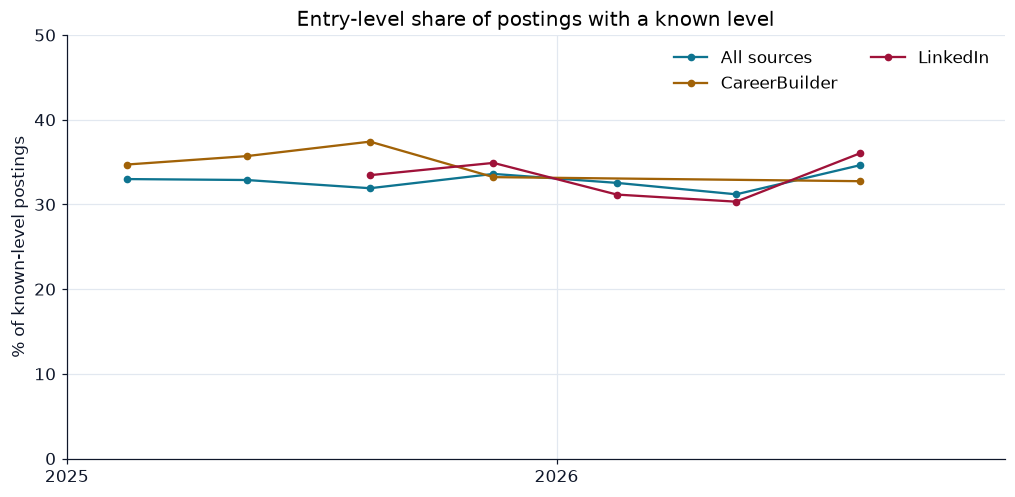

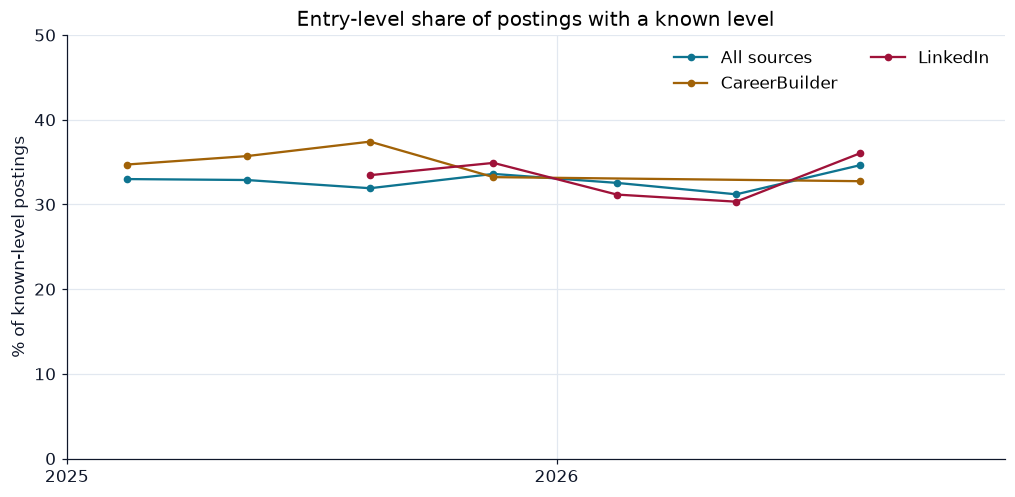

In [4]:
series = s.junior_series(df)
fig = a.trend_lines(
    series,
    "Entry-level share of postings with a known level",
    "% of known-level postings",
    start=2025,
)
fig.axes[0].set_ylim(0, 50)  # a zoomed axis would make a flat line look like a swing
a.save_chart(fig, "04-entry-share-trend")
a.save_table(
    pd.concat([f.assign(scope=n) for n, f in series.items()]).drop(columns="period_date"),
    "04-entry-share-trend",
)
fig

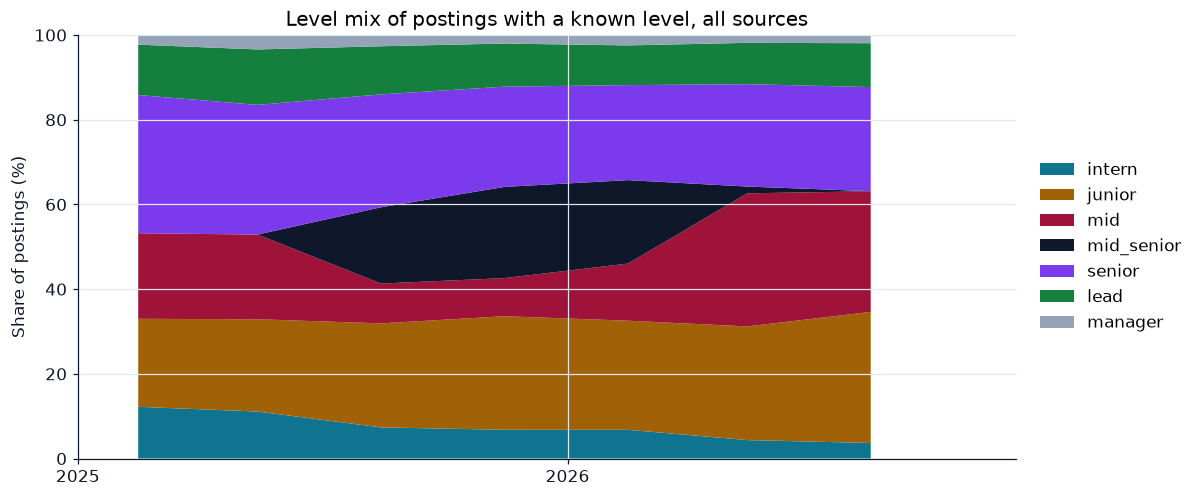

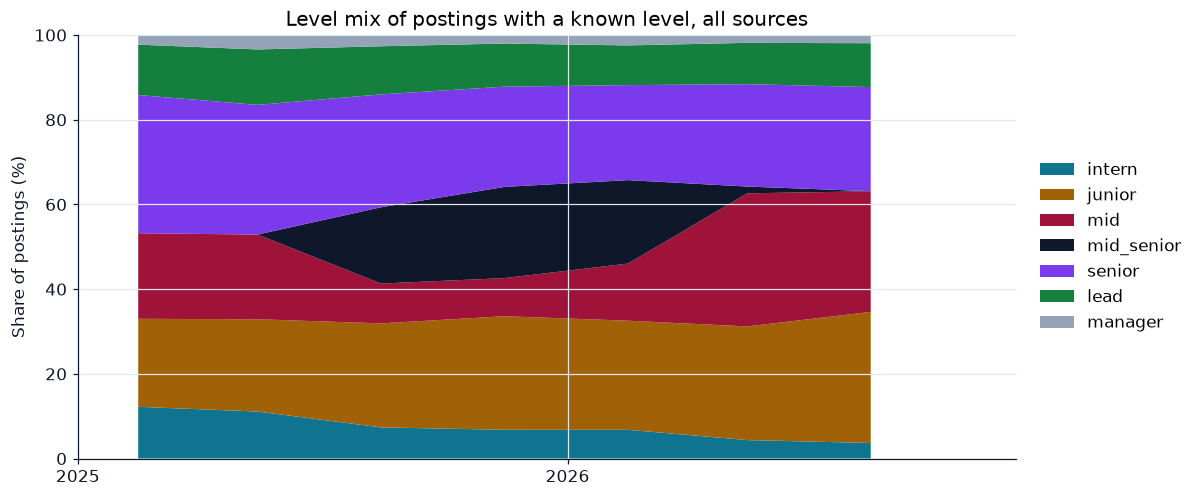

In [5]:
fig = s.chart_level_mix(df, None, "Level mix of postings with a known level, all sources")
a.save_chart(fig, "04-level-mix-all-sources")
fig

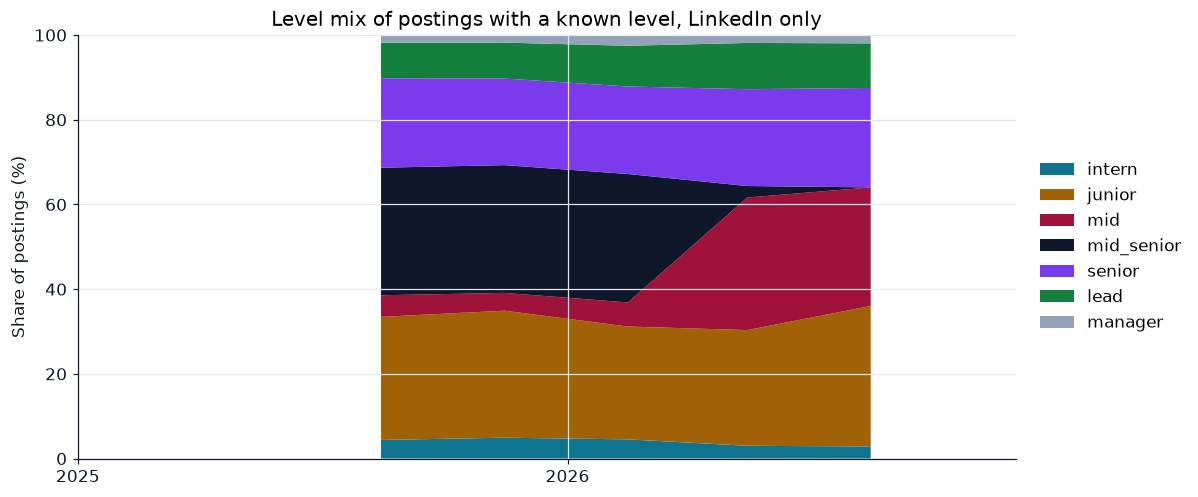

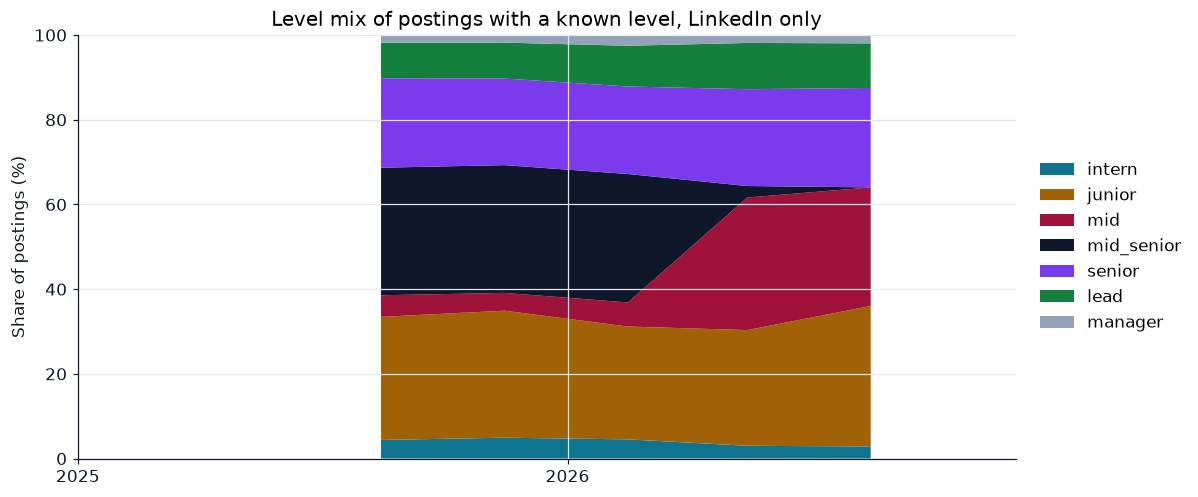

In [6]:
fig = s.chart_level_mix(
    df, "linkedin_vn", "Level mix of postings with a known level, LinkedIn only"
)
a.save_chart(fig, "04-level-mix-linkedin")
fig

## 4. Which roles let juniors in

Entry-level and senior-plus share of known-level postings per role, January 2025 onward, roles with enough postings.

,role,postings,entry,senior_plus
0,game,421,50.1,29.9
1,it_support_infra,3988,46.9,19.6
2,technical_non_software,3802,44.8,21.6
3,embedded_iot,1426,43.5,32.8
4,qa_test,6956,36.1,34.1
5,ai_ml,5375,33.7,38.6
6,software_other,6284,32.0,45.4
7,data,5436,30.6,38.3
8,mobile,1118,30.4,43.0
9,other,1844,29.3,42.1


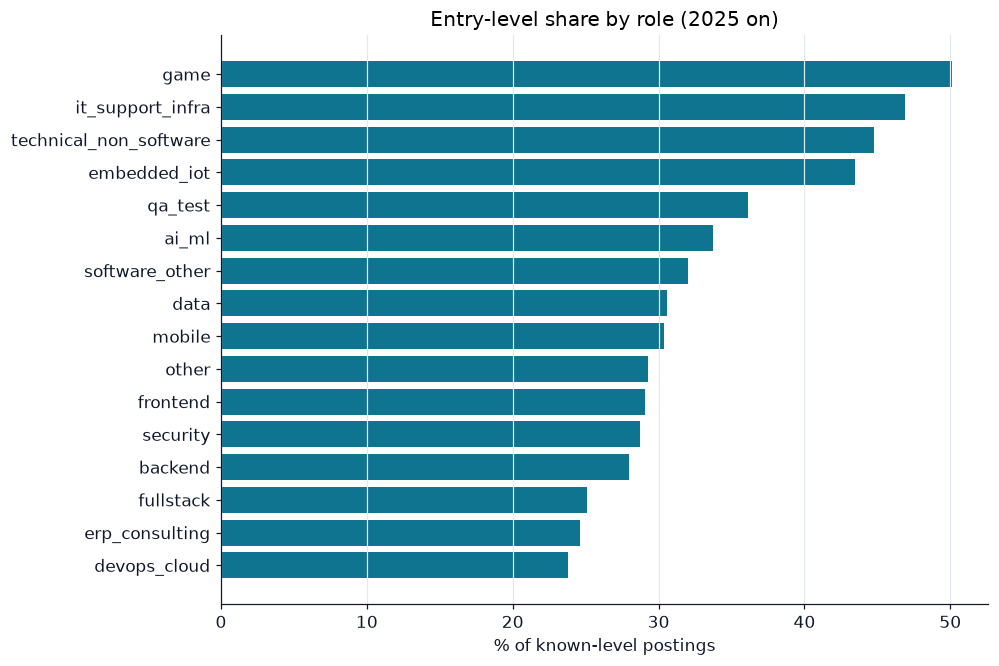

In [7]:
entry = s.entry_by_role(df)
a.save_table(entry, "04-entry-by-role")
fig = a.barh(
    entry, "role", "entry", "Entry-level share by role (2025 on)", "% of known-level postings"
)
a.save_chart(fig, "04-entry-by-role")
entry

## 5. Required experience

For the postings that state an experience requirement (2025 on, mostly from the board's own experience field): the median years and the share asking five years or more.

In [8]:
experience = s.experience_by_role(df)
a.save_table(experience, "04-experience-by-role")
experience

,role,postings,median_years,pct_5_years_plus
0,embedded_iot,749,2.0,31.5
1,it_support_infra,2463,2.0,12.6
2,other,1115,2.0,28.8
3,qa_test,4250,2.0,22.7
4,technical_non_software,2849,2.0,14.9
5,ai_ml,2802,3.0,35.7
6,backend,2964,3.0,37.2
7,data,3278,3.0,24.8
8,devops_cloud,2535,3.0,37.8
9,erp_consulting,542,3.0,31.5


## Findings

1. **Levels can be read for only part of the feed.** The share of postings with a readable level is 21–25 % in 2020–2022, 31 % in 2023, 38 % in 2024, 58 % in 2025 and 91 % in 2026, so trends start in January 2025.
2. **About one third of postings with a known level are entry level, in every large source.** From 2025: LinkedIn 34.0 %, CareerBuilder 35.0 %, CareerViet 36.8 %, Monster Asia 29.3 %. By quarter the all-source share stays between 31 % and 35 % (individual sources between 30 % and 37 %), so this window shows neither a squeeze nor an opening for juniors. Sources that state a level for few postings look different (CareerJet 24.8 %, DEjobs 14.3 %, SmartRecruiters 45.8 %), and what they do state skews senior (senior-plus 67–85 % for Jora, CareerJet and DEjobs): which postings carry a level is selective.
3. **Some roles let juniors in more than others** (2025 on, share of known-level postings that are entry): DevOps / cloud 23.8 %, ERP 24.6 %, full-stack 25.1 %, backend 28.0 %, data 30.6 %, AI / ML 33.7 %, QA 36.1 %, embedded 43.5 %, IT support 46.9 %, game 50.1 %. The technician group is 44.8 % entry, which lifts the all-roles figure.
4. **Required experience (postings that state it, 2025 on).** The median is 2 years for QA, IT support and embedded, 3 years for backend, data, DevOps, AI / ML, frontend, mobile, security and ERP, and 4 years for full-stack. Full-stack (41.7 %), general software (37.9 %), DevOps (37.8 %) and backend (37.2 %) most often ask for five years or more.
5. **Caveat.** "Entry" includes titles with junior, intern or fresher, labels such as "no experience required", and a stated requirement of up to a year. Postings whose level cannot be read are left out of every share.

**What this notebook cannot say:** anything about seniority before 2025, or whether the junior share was different in the years when most levels were unreadable.
